In [2]:
import geopandas as gpd

gdf = gpd.read_file("D:/Kush/2nd Year/projects/glacier/implementation/assets/glims/glims_download_35490/glims_polygons.shp")

print(gdf.shape)
print(gdf.columns.tolist())
print(gdf.head())

d:\Kush\2nd Year\projects\glacier\implementation\venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: GLISM/glims_download_35490/glims_polygons.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


(617777, 36)
['line_type', 'anlys_id', 'glac_id', 'anlys_time', 'area', 'db_area', 'width', 'length', 'primeclass', 'min_elev', 'mean_elev', 'max_elev', 'src_date', 'rec_status', 'glac_name', 'wgms_id', 'local_id', 'glac_stat', 'gone_date', 'gone_dt_e', 'subm_id', 'release_dt', 'proc_desc', 'rc_id', 'geog_area', 'chief_affl', 'conn_lvl', 'surge_type', 'term_type', 'gtng_o1reg', 'gtng_o2reg', 'rgi_gl_typ', 'parent_id', 'submitters', 'analysts', 'geometry']
    line_type   anlys_id         glac_id           anlys_time    area  \
0  glac_bound   715234.0  G340953E63564N  1993-09-01T00:00:00  12.414   
1  glac_bound  1048878.0  G306386E70153N  2020-09-09T00:00:00   0.000   
2  glac_bound   409177.0  G222822E58665N  2015-07-16T00:00:00   0.777   
3  glac_bound   405377.0  G217968E60885N  2015-07-16T00:00:00   8.838   
4  glac_bound   405031.0  G217723E60374N  2015-07-16T00:00:00   0.201   

     db_area  width  length  primeclass  min_elev  ...  conn_lvl  surge_type  \
0  12.413600    0.0  

# Filter 1 by area

In [3]:
print("Total polygons:", len(gdf))
print("Unique glaciers:", gdf["glac_id"].nunique())

Total polygons: 617777
Unique glaciers: 299927


In [4]:
gdf_unique = (
    gdf.sort_values("area", ascending=False)
       .drop_duplicates("glac_id")
)

gdf_unique["area"].describe()

count    2.999270e+05
mean     1.220630e+04
std      3.710601e+05
min     -9.990000e+02
25%      0.000000e+00
50%      1.100000e-01
75%      4.900000e-01
max      1.056160e+08
Name: area, dtype: float64

<Axes: >

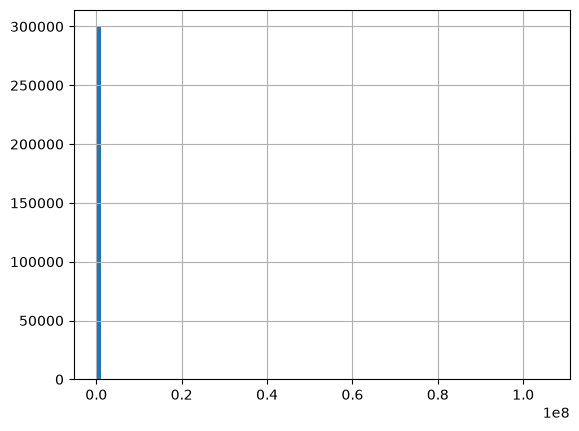

In [5]:
gdf_unique["area"].hist(bins=100)

In [6]:
gdf_unique["area"].value_counts().head(20)

area
0.000    80491
0.030     1313
0.020      990
0.050      982
0.040      862
0.060      807
0.070      661
0.054      582
0.080      572
0.051      549
0.059      501
0.090      499
0.053      488
0.052      486
0.068      486
0.055      479
0.032      473
0.063      472
0.057      467
0.100      466
Name: count, dtype: int64

In [7]:
print((gdf_unique["area"] < 0).sum())

14


In [8]:
print((gdf_unique["area"] == 0).sum())

80491


In [9]:
gdf_unique.loc[
    gdf_unique["glac_name"].isin([
        "Grosser Aletschgletscher",
        "Bezengi",
        "Ngojumba"
    ]),
    ["glac_name","area"]
]

,glac_name,area
208520,Grosser Aletschgletscher,1.056160e+08
502016,Bezengi,3.941060e+07
265298,Ngojumba,8.261000e+01
513363,Bezengi,0.000000e+00
513751,Bezengi,0.000000e+00


<Axes: >

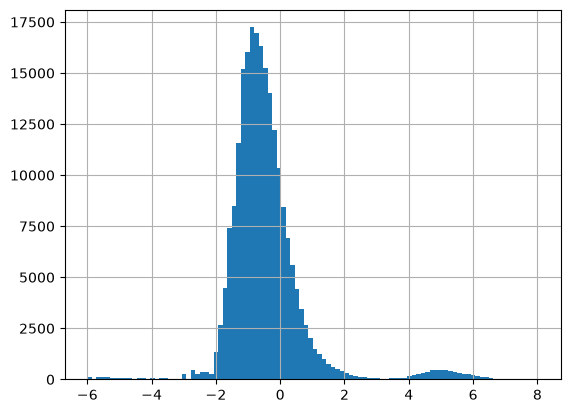

In [10]:
import numpy as np

valid = gdf_unique[
    (gdf_unique["area"] > 0)
]

np.log10(valid["area"]).hist(bins=100)

In [11]:
gdf_unique = gdf_unique[gdf_unique["area"] > 0]

In [12]:
valid = gdf_unique[gdf_unique["area"] > 0]

for threshold in [0.1, 0.5, 1, 2, 5, 10, 20, 50]:
    count = (valid["area"] >= threshold).sum()
    print(f">= {threshold:>4} km² : {count}")

>=  0.1 km² : 155043
>=  0.5 km² : 74133
>=    1 km² : 48789
>=    2 km² : 31676
>=    5 km² : 18453
>=   10 km² : 13212
>=   20 km² : 10219
>=   50 km² : 7992


### Area columns looks untrustworthy so trying the db_area

In [13]:
gdf_unique.loc[
    gdf_unique["glac_name"].isin([
        "Grosser Aletschgletscher",
        "Ngojumba",
        "Bezengi"
    ]),
    ["glac_name","area","db_area"]
]

,glac_name,area,db_area
208520,Grosser Aletschgletscher,1.056160e+08,105.6080
502016,Bezengi,3.941060e+07,39.4106
265298,Ngojumba,8.261000e+01,82.9050


In [14]:
gdf_unique["db_area"].describe()

count    219422.000000
mean          3.025412
std          43.628142
min         -11.122500
25%           0.076194
50%           0.214468
75%           0.699494
max        7537.570000
Name: db_area, dtype: float64

In [15]:
print((gdf_unique["db_area"] == 0).sum())
print((gdf_unique["db_area"] < 0).sum())


73
9


### computing area of the missing from geometry of the locations

In [16]:
import geopandas as gpd

# Equal-area projection for global area calculations
gdf_area = gdf_unique.to_crs("EPSG:6933")

In [17]:
gdf_area["geom_area_km2"] = (
    gdf_area.geometry.area / 1_000_000
)

In [18]:
gdf_area["geom_area_km2"].describe()

count    2.194220e+05
mean     3.024852e+00
std      4.363030e+01
min     -2.910383e-17
25%      7.620581e-02
50%      2.143969e-01
75%      6.991714e-01
max      7.537661e+03
Name: geom_area_km2, dtype: float64

In [19]:
gdf_area["final_area_km2"] = gdf_area["db_area"]

mask = gdf_area["db_area"] <= 0

gdf_area.loc[mask, "final_area_km2"] = (
    gdf_area.loc[mask, "geom_area_km2"]
)

In [20]:
gdf_area["final_area_km2"].describe()

count    2.194220e+05
mean     3.025526e+00
std      4.362813e+01
min     -2.910383e-17
25%      7.621775e-02
50%      2.144800e-01
75%      6.995062e-01
max      7.537570e+03
Name: final_area_km2, dtype: float64

In [21]:
print(
    (gdf_area["final_area_km2"] <= 0).sum()
)

23


In [22]:
gdf_area.loc[
    mask,
    ["glac_name","db_area","geom_area_km2","final_area_km2"]
].head(20)

,glac_name,db_area,geom_area_km2,final_area_km2
106861,Nuka Glacier,-11.122500,3.587735e+00,3.587735e+00
109857,None,-4.569890,1.434518e-01,1.434518e-01
108330,None,-0.798354,5.097853e-03,5.097853e-03
110091,None,0.000000,0.000000e+00,0.000000e+00
109925,None,0.000000,-2.910383e-17,-2.910383e-17
112732,None,0.000000,-2.910383e-17,-2.910383e-17
109412,None,-0.000000,5.820766e-17,5.820766e-17
108006,None,0.000000,2.359776e-01,2.359776e-01
112986,None,0.000000,2.161669e-01,2.161669e-01
107466,None,-0.000000,1.945469e-01,1.945469e-01


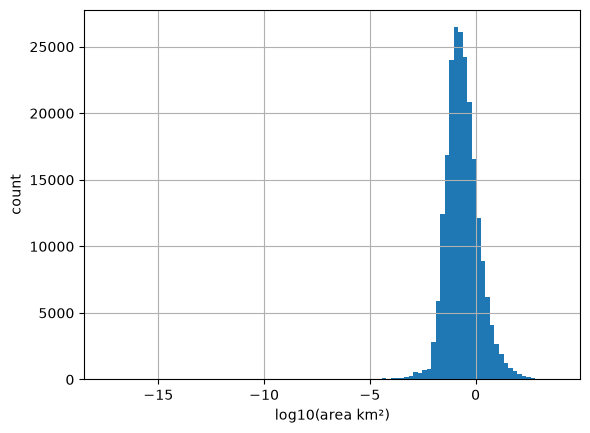

In [23]:
import numpy as np
import matplotlib.pyplot as plt

valid = gdf_area[gdf_area["final_area_km2"] > 0]

np.log10(valid["final_area_km2"]).hist(
    bins=100
)

plt.xlabel("log10(area km²)")
plt.ylabel("count")
plt.show()

In [27]:
for threshold in [0.1, 0.5, 1, 2, 5, 10, 20, 50,100,1000,5000]:
    count = (
        gdf_area["final_area_km2"] >= threshold
    ).sum()

    print(
        f">= {threshold:>4} km² : {count}"
    )

>=  0.1 km² : 151029
>=  0.5 km² : 68379
>=    1 km² : 42673
>=    2 km² : 25388
>=    5 km² : 12071
>=   10 km² : 6867
>=   20 km² : 3953
>=   50 km² : 1847
>=  100 km² : 940
>= 1000 km² : 61
>= 5000 km² : 3


In [25]:
print("Unique glaciers:", len(gdf_unique))

print("Missing geometry:",
      gdf_unique.geometry.isna().sum())

print("Empty geometry:",
      gdf_unique.geometry.is_empty.sum())

Unique glaciers: 219422
Missing geometry: 0
Empty geometry: 0


In [26]:
sample = gdf_area.sample(1000)

ratio = (
    sample["db_area"] /
    sample["geom_area_km2"]
)

print(ratio.describe())

count    1000.000000
mean        0.999696
std         0.002455
min         0.954035
25%         0.999998
50%         1.000000
75%         1.000001
max         1.001980
dtype: float64


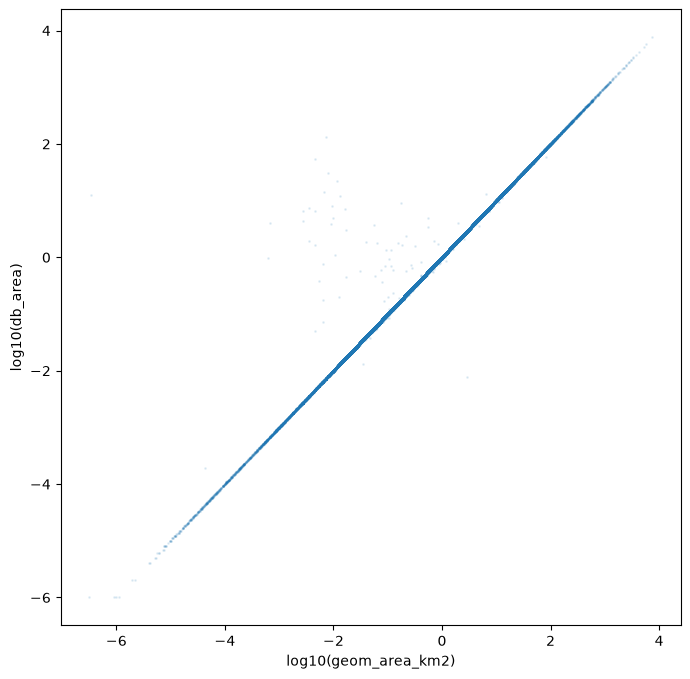

In [27]:
import matplotlib.pyplot as plt

valid = gdf_area[
    (gdf_area["db_area"] > 0) &
    (gdf_area["geom_area_km2"] > 0)
]

plt.figure(figsize=(8,8))

plt.scatter(
    np.log10(valid["geom_area_km2"]),
    np.log10(valid["db_area"]),
    s=1,
    alpha=0.1
)

plt.xlabel("log10(geom_area_km2)")
plt.ylabel("log10(db_area)")
plt.show()

the upper part confirmed db_area is trustworthy, so we will use it to filter the data.


# Second filter

In [39]:
gdf_query = gdf_area.to_crs("EPSG:4326")

In [35]:
from pystac_client import Client
import planetary_computer
import pandas as pd

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

def glacier_temporal_stats(glacier_row):

    poly = glacier_row.geometry

    bbox = list(poly.bounds)

    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime="2017-01-01/2025-12-31",
        query={"eo:cloud_cover": {"lt": 20}}
    )

    items = list(search.items())

    years = [item.datetime.year for item in items]

    year_counts = pd.Series(years).value_counts().sort_index()

    return {
        "glac_id": glacier_row["glac_id"],
        "glac_name": glacier_row["glac_name"],
        "num_scenes": len(items),
        "num_years": len(set(years)),
        "first_obs": min([item.datetime for item in items]) if items else None,
        "last_obs": max([item.datetime for item in items]) if items else None,
        "year_counts": year_counts.to_dict()
    }

In [40]:
aletsch = gdf_query[gdf_query["glac_name"]=="Grosser Aletschgletscher"].iloc[0]

ngojumba = gdf_query[gdf_query["glac_name"]=="Ngojumba"].iloc[0]

taku = gdf_query[gdf_query["glac_name"].str.contains(
    "Taku",
    case=False,
    na=False
)].iloc[0]

bezengi = gdf_query[gdf_query["glac_name"]=="Bezengi"].iloc[0]

christian = gdf_query[gdf_query["glac_name"].str.contains(
    "CHRISTIAN IV",
    case=False,
    na=False
)].iloc[0]

In [41]:
glaciers = [
    aletsch,
    ngojumba,
    taku,
    bezengi,
    christian
]

results = []

for g in glaciers:

    print("Processing:", g["glac_name"])

    results.append(
        glacier_temporal_stats(g)
    )

Processing: Grosser Aletschgletscher
Processing: Ngojumba
Processing: Taku Glacier
Processing: Bezengi
Processing: CHRISTIAN IV GL.


In [42]:
for r in results:

    print("\n" + "="*60)

    print("Name:", r["glac_name"])

    print("Scenes:", r["num_scenes"])

    print("Years:", r["num_years"])

    print("First:", r["first_obs"])

    print("Last:", r["last_obs"])

    print("Per year:")

    print(r["year_counts"])


Name: Grosser Aletschgletscher
Scenes: 371
Years: 9
First: 2017-02-16 10:21:01.026000+00:00
Last: 2025-12-31 10:24:41.025000+00:00
Per year:
{2017: 28, 2018: 35, 2019: 32, 2020: 43, 2021: 34, 2022: 62, 2023: 58, 2024: 28, 2025: 51}

Name: Ngojumba
Scenes: 386
Years: 9
First: 2017-09-05 04:47:01.026000+00:00
Last: 2025-12-27 04:51:19.024000+00:00
Per year:
{2017: 7, 2018: 10, 2019: 11, 2020: 15, 2021: 14, 2022: 84, 2023: 112, 2024: 66, 2025: 67}

Name: Taku Glacier
Scenes: 343
Years: 9
First: 2017-01-07 20:28:21.026000+00:00
Last: 2025-12-26 20:27:49.024000+00:00
Per year:
{2017: 12, 2018: 47, 2019: 50, 2020: 45, 2021: 39, 2022: 43, 2023: 39, 2024: 43, 2025: 25}

Name: Bezengi
Scenes: 187
Years: 9
First: 2017-06-14 08:00:11.026000+00:00
Last: 2025-12-21 08:03:51.024000+00:00
Per year:
{2017: 14, 2018: 17, 2019: 17, 2020: 18, 2021: 13, 2022: 26, 2023: 35, 2024: 16, 2025: 31}

Name: CHRISTIAN IV GL.
Scenes: 4754
Years: 9
First: 2017-02-28 14:21:21.026000+00:00
Last: 2025-11-06 13:42:49.0

In [43]:
import pandas as pd

summary = pd.DataFrame([
    {
        "glac_name": r["glac_name"],
        "num_scenes": r["num_scenes"],
        "num_years": r["num_years"]
    }
    for r in results
])

summary

,glac_name,num_scenes,num_years
0,Grosser Aletschgletscher,371,9
1,Ngojumba,386,9
2,Taku Glacier,343,9
3,Bezengi,187,9
4,CHRISTIAN IV GL.,4754,9


In [44]:
for r in results:
    if r["num_years"] < 7:
        print(r["glac_name"])
        print(r["year_counts"])

In [45]:
candidate_glaciers = gdf_area[
    gdf_area["final_area_km2"] >= 1
]

sample_100 = candidate_glaciers.sample(
    100,
    random_state=42
)

In [46]:
r = results[4]  # Christian IV
print(r["year_counts"])

{2017: 501, 2018: 572, 2019: 664, 2020: 538, 2021: 653, 2022: 378, 2023: 646, 2024: 331, 2025: 471}


In [48]:
gdf_query["geog_area"].value_counts().head(30)

geog_area
Randolph Glacier Inventory; Umbrella RC for merging the RGI into GLIMS    110768
Various (GlobGlacier)                                                      30828
China                                                                      26773
Northern Cordillera                                                        15196
European Alps                                                               7323
Conterminous USA                                                            6060
Caucausus Region                                                            3874
Himalaya (India, Nepal, Bhutan)                                             3633
Canada                                                                      2592
Svalbard, Jan Mayen, and Bouvet                                             2334
Juneau area                                                                 1650
Khumbu Area                                                                 1038
Italy             

# final filtering 

In [49]:
area_filtered = gdf_area[
    gdf_area["final_area_km2"] >= 5
].copy()

print("After area filter:", len(area_filtered))

After area filter: 12071


In [53]:
area_5km = gdf_area[
    gdf_area["final_area_km2"] >= 5
].copy()

print("Glaciers >= 5 km²:", len(area_5km))

region_counts = area_5km["geog_area"].value_counts()

print(region_counts.head(30))

Glaciers >= 5 km²: 12071
geog_area
Randolph Glacier Inventory; Umbrella RC for merging the RGI into GLIMS    6707
Various (GlobGlacier)                                                     1371
Svalbard, Jan Mayen, and Bouvet                                            954
China                                                                      747
Canada                                                                     728
Northern Cordillera                                                        617
East Central Greenland                                                     252
Himalaya (India, Nepal, Bhutan)                                            207
Juneau area                                                                 76
Khumbu Area                                                                 71
European Alps                                                               68
Greenland                                                                   63
Caucausus Region 

In [54]:
area_5km[
    area_5km["geog_area"].str.contains(
        "Randolph|GlobGlacier",
        case=False,
        na=False
    )
][
    ["glac_id","glac_name","geog_area","final_area_km2"]
].head(20)

,glac_id,glac_name,geog_area,final_area_km2
499328,G016345E67139N,Salajiegna,Randolph Glacier Inventory; Umbrella RC for me...,21.9471
343163,G344790E81287N,None,Randolph Glacier Inventory; Umbrella RC for me...,7537.5700
361529,G333975E69553N,None,Randolph Glacier Inventory; Umbrella RC for me...,4239.8300
361016,G332658E69567N,None,Randolph Glacier Inventory; Umbrella RC for me...,3679.0100
7026,G219787E60289N,Seward Glacier,Randolph Glacier Inventory; Umbrella RC for me...,3362.6600
18342,G217991E60521N,Bering Glacier,Randolph Glacier Inventory; Umbrella RC for me...,3025.1100
345832,G330976E68786N,None,Randolph Glacier Inventory; Umbrella RC for me...,2975.9200
12306,G220740E60158N,Hubbard Glacier,Randolph Glacier Inventory; Umbrella RC for me...,2834.4900
194513,G286943E70021N,"Barnes Ice Cap South Dome N Slope,",Randolph Glacier Inventory; Umbrella RC for me...,2771.4100
198997,G278488E75058N,None,Randolph Glacier Inventory; Umbrella RC for me...,2622.8100


In [58]:
print(area_5km.crs)

EPSG:6933


In [59]:
area_5km_wgs84 = area_5km.to_crs("EPSG:4326")

area_5km_wgs84["lat"] = area_5km_wgs84.geometry.centroid.y
area_5km_wgs84["lon"] = area_5km_wgs84.geometry.centroid.x

C:\Users\KUSH\AppData\Local\Temp\ipykernel_5952\2712480251.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area_5km_wgs84["lat"] = area_5km_wgs84.geometry.centroid.y
C:\Users\KUSH\AppData\Local\Temp\ipykernel_5952\2712480251.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area_5km_wgs84["lon"] = area_5km_wgs84.geometry.centroid.x


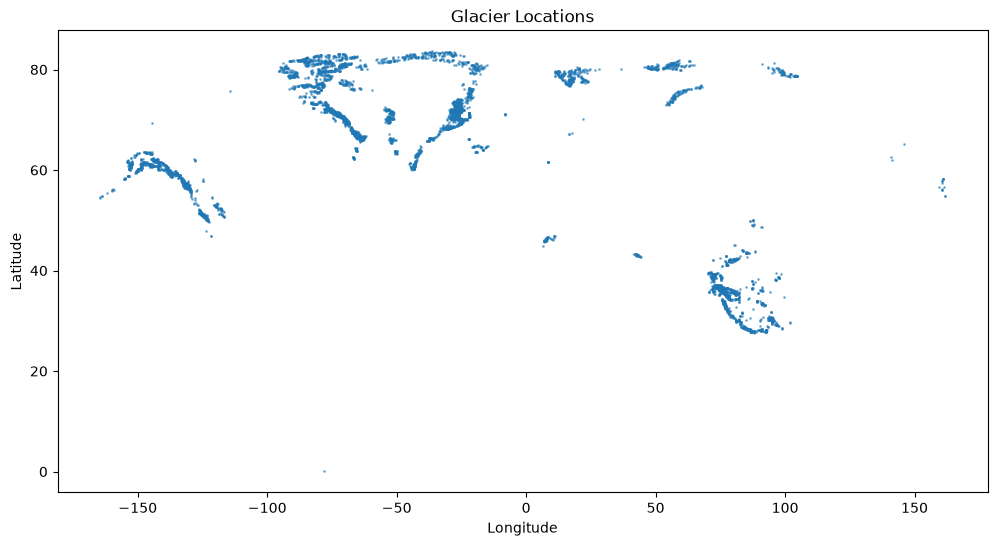

In [61]:
import matplotlib.pyplot as plt

sample = area_5km_wgs84.sample(
    min(5000, len(area_5km_wgs84)),
    random_state=42
)

plt.figure(figsize=(12,6))

plt.scatter(
    sample["lon"],
    sample["lat"],
    s=1,
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Glacier Locations")

plt.show()

In [28]:
candidate = gdf_area[
    (gdf_area["final_area_km2"] >= 5) &
    (gdf_area["final_area_km2"] <= 1000)
].copy()

print("Candidate glaciers:", len(candidate))

Candidate glaciers: 12010


In [29]:
candidate = candidate.to_crs("EPSG:4326")

In [30]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

def get_num_years(glacier_row):

    bbox = list(glacier_row.geometry.bounds)

    try:

        search = catalog.search(
            collections=["sentinel-2-l2a"],
            bbox=bbox,
            datetime="2017-01-01/2025-12-31",
            query={"eo:cloud_cover": {"lt": 20}}
        )

        items = list(search.items())

        years = set(
            item.datetime.year
            for item in items
        )

        return len(years)

    except Exception as e:

        print(
            f"Failed: {glacier_row['glac_id']} | {e}"
        )

        return None

In [31]:
from tqdm import tqdm
import pandas as pd

results = []

for idx, (_, glacier) in enumerate(
    tqdm(candidate.iterrows(),
         total=len(candidate))
):

    num_years = get_num_years(glacier)

    results.append({
        "glac_id": glacier["glac_id"],
        "num_years": num_years
    })

    # save every 100 glaciers

    if idx % 100 == 0:

        pd.DataFrame(results).to_csv(
            "temporal_progress.csv",
            index=False
        )

  1%|          | 139/12010 [13:30<19:13:02,  5.83s/it]


KeyboardInterrupt: 

In [35]:
temporal_df = pd.DataFrame(results)

temporal_df.to_csv(
    "temporal_all.csv",
    index=False
)

In [36]:
valid = temporal_df.dropna()

print("Total:", len(valid))

print(
    "< 9 years:",
    (valid["num_years"] < 9).sum()
)

print(
    "< 7 years:",
    (valid["num_years"] < 7).sum()
)

print(
    "Exactly 9 years:",
    (valid["num_years"] == 9).sum()
)

Total: 139
< 9 years: 0
< 7 years: 0
Exactly 9 years: 139


In [34]:
# glaciers with area between 5 and 1000 km²

area_5_1000 = gdf_area[
    (gdf_area["final_area_km2"] >= 5) &
    (gdf_area["final_area_km2"] <= 1000)
].copy()

print("Total glaciers:", len(area_5_1000))

# count per region
region_counts = (
    area_5_1000["geog_area"]
    .value_counts()
)

print(region_counts)

Total glaciers: 12010
geog_area
Randolph Glacier Inventory; Umbrella RC for merging the RGI into GLIMS    6669
Various (GlobGlacier)                                                     1369
Svalbard, Jan Mayen, and Bouvet                                            949
China                                                                      747
Canada                                                                     722
Northern Cordillera                                                        617
East Central Greenland                                                     242
Himalaya (India, Nepal, Bhutan)                                            207
Juneau area                                                                 76
Khumbu Area                                                                 71
European Alps                                                               68
Greenland                                                                   63
Caucausus Region    